In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

ds = load_dataset("dair-ai/emotion", "unsplit")
df = ds["train"].to_pandas()

print("Dataset shape:", df.shape)
print(df.head())
print("Class counts:")
print(df["label"].value_counts().sort_index())

Dataset shape: (416809, 2)
                                                text  label
0  i feel awful about it too because it s my job ...      0
1                              im alone i feel awful      0
2  ive probably mentioned this before but i reall...      1
3           i was feeling a little low few days back      0
4  i beleive that i am much more sensitive to oth...      2
Class counts:
label
0    121187
1    141067
2     34554
3     57317
4     47712
5     14972
Name: count, dtype: int64


In [ ]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=["text", "label"]).copy()
df["label"] = df["label"].astype("int32")

In [5]:
df['label'].value_counts()

label
1    140779
0    120989
3     57235
4     47664
2     34497
5     14959
Name: count, dtype: int64

In [6]:
print("Unique labels:", sorted(df["label"].unique()))


Unique labels: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]


In [ ]:

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\\S+|www\\S+", "", text)
    text = re.sub(r"[^a-z\\s]", " ", text)
    text = re.sub(r"\\s+", " ", text)
    return text.strip()

In [9]:
df['clean_text']=df['text'].apply(clean_text)

In [10]:
X = df["clean_text"].astype(str)
y = df["label"].astype("int32")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=(0.15 / 0.85),
    random_state=SEED,
    stratify=y_train
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 291285
Validation: 62419
Test: 62419


In [ ]:
MAX_VOCAB = 20000
MAX_LEN = 60

tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

vocab_size = min(MAX_VOCAB, len(tokenizer.word_index) + 1)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Vocabulary size:", vocab_size)
print("Train shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)

print("Test shape:", X_test_pad.shape)

Vocabulary size: 20000
Train shape: (291285, 60)
Validation shape: (62419, 60)
Test shape: (62419, 60)


In [12]:
sentences = [text.split() for text in X_train]
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # Skip-gram
    epochs=15,
    seed=SEED
)

print("Word2Vec vocabulary:", len(w2v_model.wv))

Word2Vec vocabulary: 34202


In [13]:
EMBEDDING_DIM = 100
rng = np.random.default_rng(SEED)

# Random initialization for words missing from Word2Vec; these remain trainable
embedding_matrix = rng.normal(
    loc=0.0, scale=0.05, size=(vocab_size, EMBEDDING_DIM)
).astype("float32")
embedding_matrix[0] = 0.0  # padding token

found = 0
for word, index in tokenizer.word_index.items():
    if index < vocab_size and word in w2v_model.wv:
        embedding_matrix[index] = w2v_model.wv[word]
        found += 1

print("Embedding matrix:", embedding_matrix.shape)
print("Words initialized from Word2Vec:", found)
print("Word2Vec coverage:", round(found / max(1, vocab_size - 1) * 100, 2), "%")

Embedding matrix: (20000, 100)
Words initialized from Word2Vec: 19998
Word2Vec coverage: 99.99 %


In [14]:
# 9. Improved Word2Vec + Bidirectional LSTM model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,       
        trainable=True
    ),
    Bidirectional(LSTM(64)),
    Dropout(0.25),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(6, activation="softmax")
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,000 (7.63 MB)

 Trainable params: 2,000,000 (7.63 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [16]:
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 492s 193ms/step - accuracy: 0.8957 - loss: 0.2479 - val_accuracy: 0.9400 - val_loss: 0.0938 - learning_rate: 0.0010
Epoch 2/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 416s 183ms/step - accuracy: 0.9405 - loss: 0.0956 - val_accuracy: 0.9419 - val_loss: 0.0895 - learning_rate: 0.0010
Epoch 3/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 742s 314ms/step - accuracy: 0.9419 - loss: 0.0877 - val_accuracy: 0.9418 - val_loss: 0.0913 - learning_rate: 0.0010
Epoch 4/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.9433 - loss: 0.0842
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 620s 272ms/step - accuracy: 0.9433 - loss: 0.0842 - val_accuracy: 0.9426 - val_loss: 0.0896 - learning_rate: 0.0010
Epoch 5/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 537s 236ms/step - accuracy: 0.9447 - loss: 0.0809 - val_accuracy: 0.9430 - val_loss: 0.0921 - learning_rate: 5.0000e-04
Epoch 6/20
2276/2276 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/

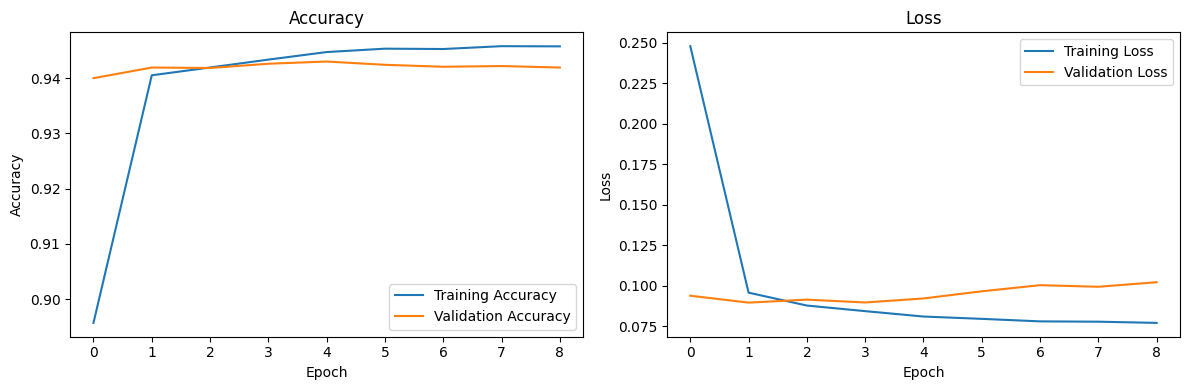

In [17]:
# 12. Plot training and validation accuracy/loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.tight_layout()
plt.show()

In [18]:
# 13. Evaluate training and held-out test accuracy
train_loss, train_acc = model.evaluate(X_train_pad, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test_pad, y_test, verbose=0)

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Testing Accuracy:  {test_acc * 100:.2f}%")
print(f"Training Loss: {train_loss:.4f}")
print(f"Testing Loss:  {test_loss:.4f}")

Training Accuracy: 94.48%
Testing Accuracy:  93.87%
Training Loss: 0.0786
Testing Loss:  0.0992


In [28]:
# 15. Predict emotion for a new sentence
emotion_labels = {
    0: "Sad",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise"
}

def predict_emotion(sentence):
    cleaned = clean_text(sentence)
    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence, maxlen=MAX_LEN, padding="post", truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_index]) * 100

    print("Input:", sentence)
    print("Predicted emotion:", emotion_labels[predicted_index])
    print("Label:", predicted_index)
    print("Confidence:", round(confidence, 2), "%")

    return emotion_labels[predicted_index]

predict_emotion("Did you hear that strange noise?")

Input: Did you hear that strange noise?
Predicted emotion: Fear
Label: 4
Confidence: 57.99 %


'Fear'

In [29]:
# 16. Save the trained model and tokenizer
import pickle

model.save("emotion_word2vec_bilstm.keras")

with open("emotion_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Model and tokenizer saved.")

Model and tokenizer saved.


In [3]:
import numpy as np
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import load_model

In [6]:
import pickle

In [17]:
model=load_model('emotion_word2vec_bilstm.keras')
with open("emotion_tokenizer.pkl","rb") as file:
    tokenizer =pickle.load(file)

In [18]:
emotion_labels = {
    0: "Sad",
    1: "Joy",
    2: "Love",
    3: "Anger",
    4: "Fear",
    5: "Surprise",
}
print("Model and tokenizer loaded.")

Model and tokenizer loaded.


In [19]:
MAX_LEN=60

In [20]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [28]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def predict_emotion(sentence):
    cleaned = clean_text(sentence)
    if not cleaned:
        print("No English letters found in the text.")
        return None

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(sequence, maxlen=MAX_LEN, padding="post", truncating="post")

    probs = model.predict(padded, verbose=0)[0]
    best = int(np.argmax(probs))

    print("Input:", sentence)
    print(f"Predicted emotion: {emotion_labels[best]}  ({probs[best] * 100:.2f}%)")
    

    return emotion_labels[best]

In [31]:
predict_emotion("he fucking person distruct me")

Input: he fucking person distruct me
Predicted emotion: Anger  (95.61%)


'Anger'